<a href="https://colab.research.google.com/github/Nazarchona/Tutorial/blob/main/%D0%9B%D0%A05_%D0%93%D1%83%D1%94%D0%B2_%D0%A4%D0%86%D0%A24_10_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [3]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("Базові бібліотеки імпортовано.")


Базові бібліотеки імпортовано.


In [4]:
# У Colab завантажте CSV-файл з комп'ютера.
# Якщо файл уже знаходиться в /content, можна вказати його шлях у DATA_PATH.
DATA_PATH = None

try:
    from google.colab import files
    if DATA_PATH is None:
        uploaded = files.upload()
        csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
        if csv_files:
            DATA_PATH = csv_files[0]
except ImportError:
    # Для локального Jupyter Notebook покладіть CSV поруч із ноутбуком
    pass

if DATA_PATH is None:
    candidates = [
        "kaggel_weather_2013_to_2024.csv",
        "kaggle_weather_2013_to_2024.csv",
        "daily_climate.csv"
    ]
    DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)

if DATA_PATH is None or not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "CSV не знайдено. Завантажте файл з Kaggle у Colab і повторно запустіть цю клітинку."
    )

df_raw = pd.read_csv(DATA_PATH)
print("Файл:", DATA_PATH)
print("Розмір датасету:", df_raw.shape)
display(df_raw.head())


Saving kaggel_weather_2013_to_2024.csv to kaggel_weather_2013_to_2024.csv
Файл: kaggel_weather_2013_to_2024.csv
Розмір датасету: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,conditions,Year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,22.3,1008.3,"Rain, Partially cloudy",2013,4,6,104,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,17.6,1005.1,Clear,2013,4,0,105,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,27.7,1001.7,Partially cloudy,2013,4,1,106,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,22.3,1002.5,Clear,2013,4,2,107,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,12.4,1003.4,Clear,2013,4,3,108,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [6]:
print("Назви колонок:")
print(df_raw.columns.tolist())

print("\\nІнформація про типи даних:")
df_raw.info()

print("\\nОпис числових колонок:")
display(df_raw.describe(include="all").T)


Назви колонок:
['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']
\nІнформація про типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feels

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,3557.0,NaN,NaN,NaN,1778.0,1026.961781,0.0,889.0,1778.0,2667.0,3556.0
DATE,3557,3556,5/1/2022,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tempmax,3557.0,NaN,NaN,NaN,31.367501,7.073934,9.1,26.4,33.0,36.0,47.9
tempmin,3557.0,NaN,NaN,NaN,20.076132,7.568531,2.0,13.0,22.0,26.9,34.8
temp,3557.0,NaN,NaN,NaN,25.403374,7.325541,6.5,19.1,27.7,31.0,39.5
feelslikemax,3557.0,NaN,NaN,NaN,34.28018,9.651743,7.9,26.3,35.4,42.7,57.7
feelslikemin,3557.0,NaN,NaN,NaN,20.938769,9.004827,0.3,13.0,22.0,28.0,41.1
feelslike,3557.0,NaN,NaN,NaN,27.306803,9.301636,5.7,19.1,28.4,35.4,47.0
humidity,3557.0,NaN,NaN,NaN,63.75544,18.129251,16.1,53.0,65.8,76.9,99.3
precip,3557.0,NaN,NaN,NaN,2.459033,10.636255,0.0,0.0,0.0,0.0,203.047


Підготовка даних

In [7]:
# Автоматично визначаємо колонку з датою за назвою.
date_candidates = [c for c in df_raw.columns if any(k in c.lower() for k in ["date", "datetime", "time", "дата"])]
if not date_candidates:
    # Спробувати розпізнати колонку, у якій більшість значень є датами
    for c in df_raw.columns:
        parsed = pd.to_datetime(df_raw[c], errors="coerce")
        if parsed.notna().mean() > 0.8:
            date_candidates.append(c)
            break
if not date_candidates:
    raise ValueError("Не вдалося знайти колонку з датою. Перевірте назви колонок у df_raw.")

DATE_COL = date_candidates[0]
df = df_raw.copy()
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df = df.dropna(subset=[DATE_COL]).sort_values(DATE_COL)

# Видаляємо повністю порожні колонки та дублікати за датою (залишаємо останній запис).
df = df.dropna(axis=1, how="all")
df = df.drop_duplicates(subset=[DATE_COL], keep="last")
df = df.set_index(DATE_COL)
df.index.name = "date"

# Перетворюємо значення на числові там, де це можливо.
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Залишаємо числові колонки, які містять хоча б одне значення.
df = df.select_dtypes(include=[np.number])
df = df.dropna(axis=1, how="all")

# Заповнення пропусків інтерполяцією в часовому порядку.
df = df.interpolate(method="time", limit_direction="both")
df = df.dropna(how="all")

print("Початок періоду:", df.index.min())
print("Кінець періоду:", df.index.max())
print("Кількість рядків після обробки:", len(df))
print("Колонки:", df.columns.tolist())
display(df.head())


Початок періоду: 2013-04-14 00:00:00
Кінець періоду: 2024-11-30 00:00:00
Кількість рядків після обробки: 3556
Колонки: ['Unnamed: 0', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,Year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
date,,,,,,,,,,,,,,,,,,,,,,,,,,,
2013-04-14,0,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,22.3,1008.3,2013,4,6,104,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,1,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,17.6,1005.1,2013,4,0,105,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,2,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,27.7,1001.7,2013,4,1,106,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,3,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,22.3,1002.5,2013,4,2,107,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,4,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,12.4,1003.4,2013,4,3,108,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [8]:
# Інформація про структуру датасету
print("Розмір датасету:")
print(df.shape)

print("\nНазви стовпців:")
print(df.columns.tolist())

print("\nТипи даних та кількість непорожніх значень:")
df.info()

print("\nПерші 5 рядків датасету:")
display(df.head())


Розмір датасету:
(3556, 27)

Назви стовпців:
['Unnamed: 0', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']

Типи даних та кількість непорожніх значень:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3556 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3556 non-null   int64  
 1   tempmax                3556 non-null   float64
 2   tempmin                3556 non-null   float64
 3   temp                   3556 non-null   float64
 4   feelslikemax           3556 non-null   float64
 5   feelslikemin   

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,Year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
date,,,,,,,,,,,,,,,,,,,,,,,,,,,
2013-04-14,0,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,22.3,1008.3,2013,4,6,104,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,1,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,17.6,1005.1,2013,4,0,105,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,2,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,27.7,1001.7,2013,4,1,106,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,3,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,22.3,1002.5,2013,4,2,107,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,4,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,12.4,1003.4,2013,4,3,108,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [9]:
print("Пропущені значення за колонками:")
display(df.isna().sum().to_frame("missing_count"))

# Обираємо цільову колонку температури за типовими назвами.
temp_candidates = [
    c for c in df.columns
    if any(k in c.lower() for k in ["meantemp", "mean_temp", "temperature", "temp", "температур"])
]
if temp_candidates:
    TARGET_COL = temp_candidates[0]
else:
    # Якщо назва незрозуміла, використовуємо першу числову колонку.
    TARGET_COL = df.columns[0]

series = df[TARGET_COL].astype(float).asfreq("D")
# Якщо у календарному ряді є дні без спостережень, заповнюємо їх інтерполяцією.
series = series.interpolate(method="time", limit_direction="both").dropna()

print(f"Цільовий показник: {TARGET_COL}")
print(f"Кількість щоденних спостережень: {len(series)}")
display(series.to_frame().head())


Пропущені значення за колонками:


,missing_count
Unnamed: 0,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0


Цільовий показник: tempmax
Кількість щоденних спостережень: 4249


,tempmax
date,
2013-04-14,37.7
2013-04-15,37.5
2013-04-16,40.1
2013-04-17,36.4
2013-04-18,37.5


Графік температури

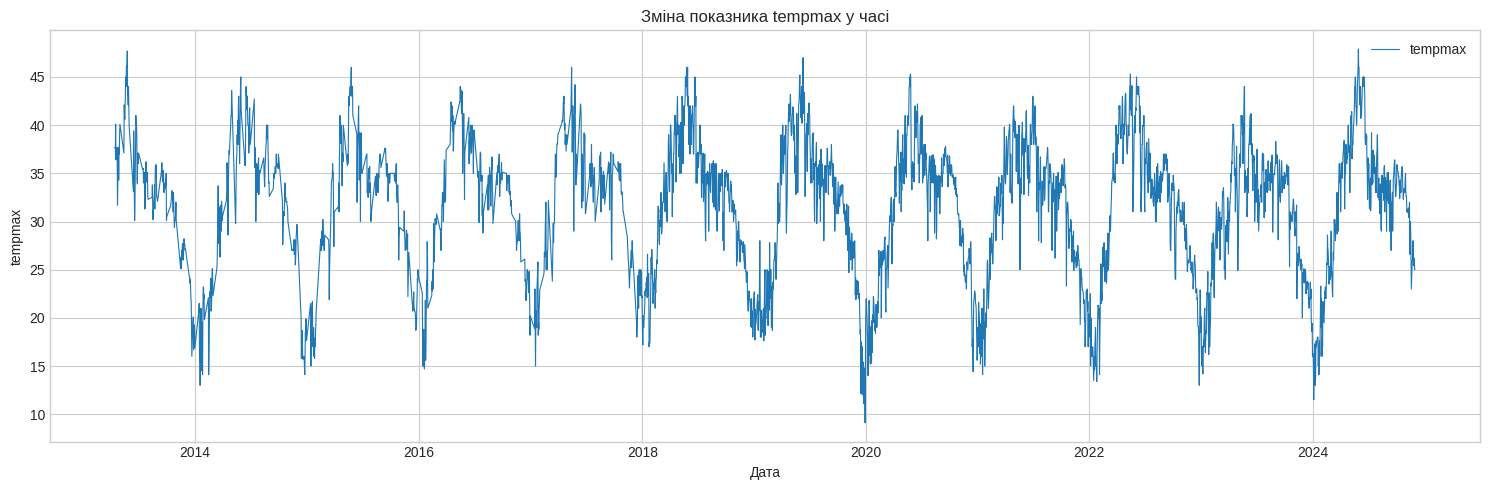

In [10]:
plt.figure(figsize=(15, 5))
plt.plot(series.index, series.values, linewidth=0.8, label=TARGET_COL)
plt.title(f"Зміна показника {TARGET_COL} у часі")
plt.xlabel("Дата")
plt.ylabel(TARGET_COL)
plt.legend()
plt.tight_layout()
plt.show()


Ковзне середнє

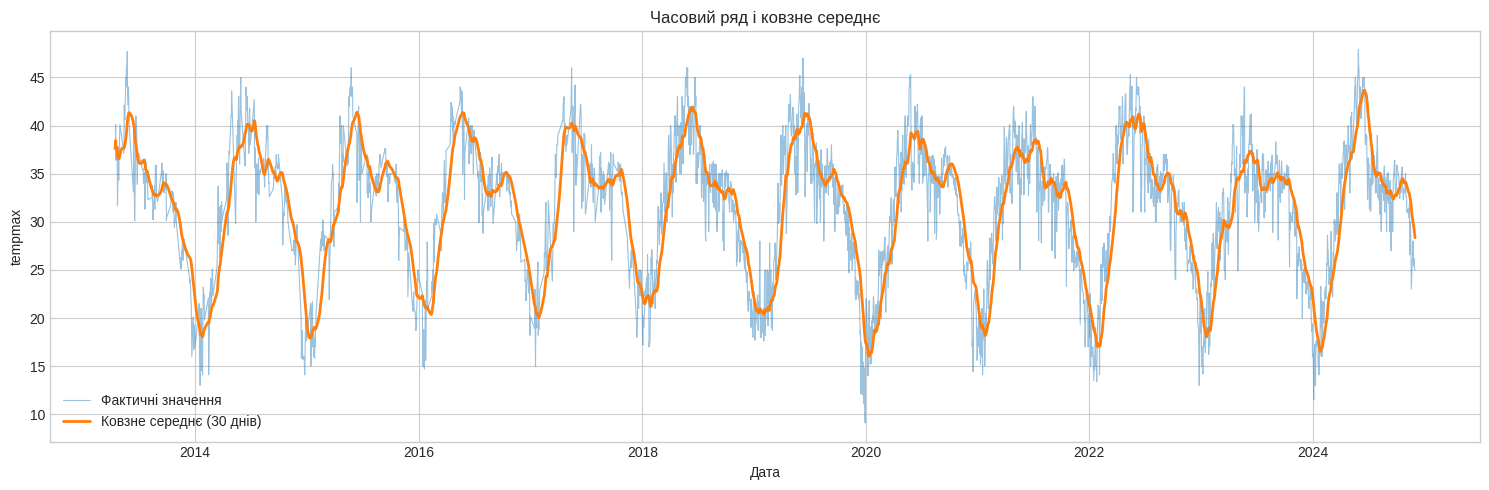

In [11]:
window = 30
rolling_mean = series.rolling(window=window, min_periods=1).mean()

plt.figure(figsize=(15, 5))
plt.plot(series.index, series, alpha=0.45, linewidth=0.8, label="Фактичні значення")
plt.plot(rolling_mean.index, rolling_mean, linewidth=2, label=f"Ковзне середнє ({window} днів)")
plt.title("Часовий ряд і ковзне середнє")
plt.xlabel("Дата")
plt.ylabel(TARGET_COL)
plt.legend()
plt.tight_layout()
plt.show()


Розподіл температури

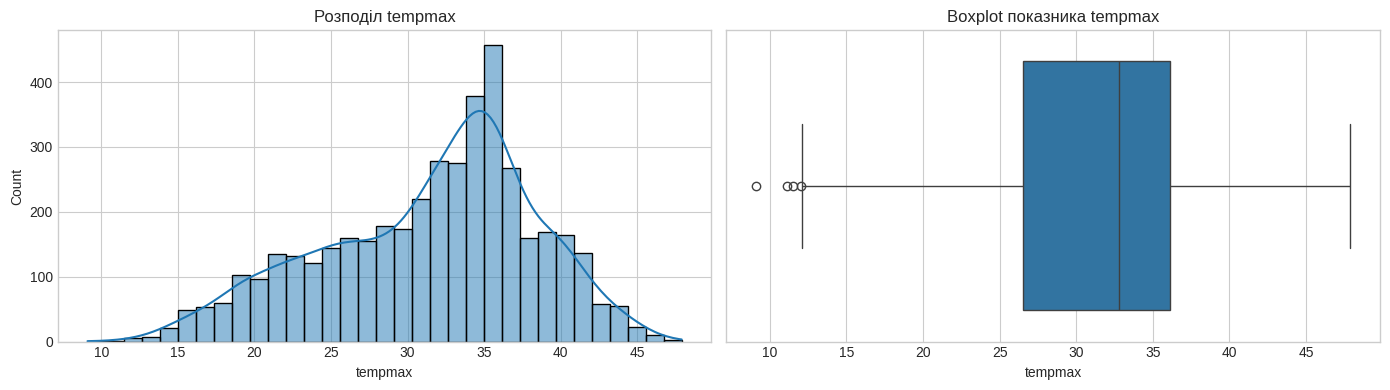

Кількість потенційних викидів за правилом IQR: 4
Викиди не видаляються автоматично, оскільки екстремальні кліматичні значення можуть бути реальними.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(series, kde=True, ax=axes[0])
axes[0].set_title(f"Розподіл {TARGET_COL}")
axes[0].set_xlabel(TARGET_COL)

sns.boxplot(x=series, ax=axes[1])
axes[1].set_title(f"Boxplot показника {TARGET_COL}")
axes[1].set_xlabel(TARGET_COL)
plt.tight_layout()
plt.show()

q1, q3 = series.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = series[(series < lower) | (series > upper)]
print(f"Кількість потенційних викидів за правилом IQR: {len(outliers)}")
print("Викиди не видаляються автоматично, оскільки екстремальні кліматичні значення можуть бути реальними.")


Аналіз автокореляції
ACF

PACF

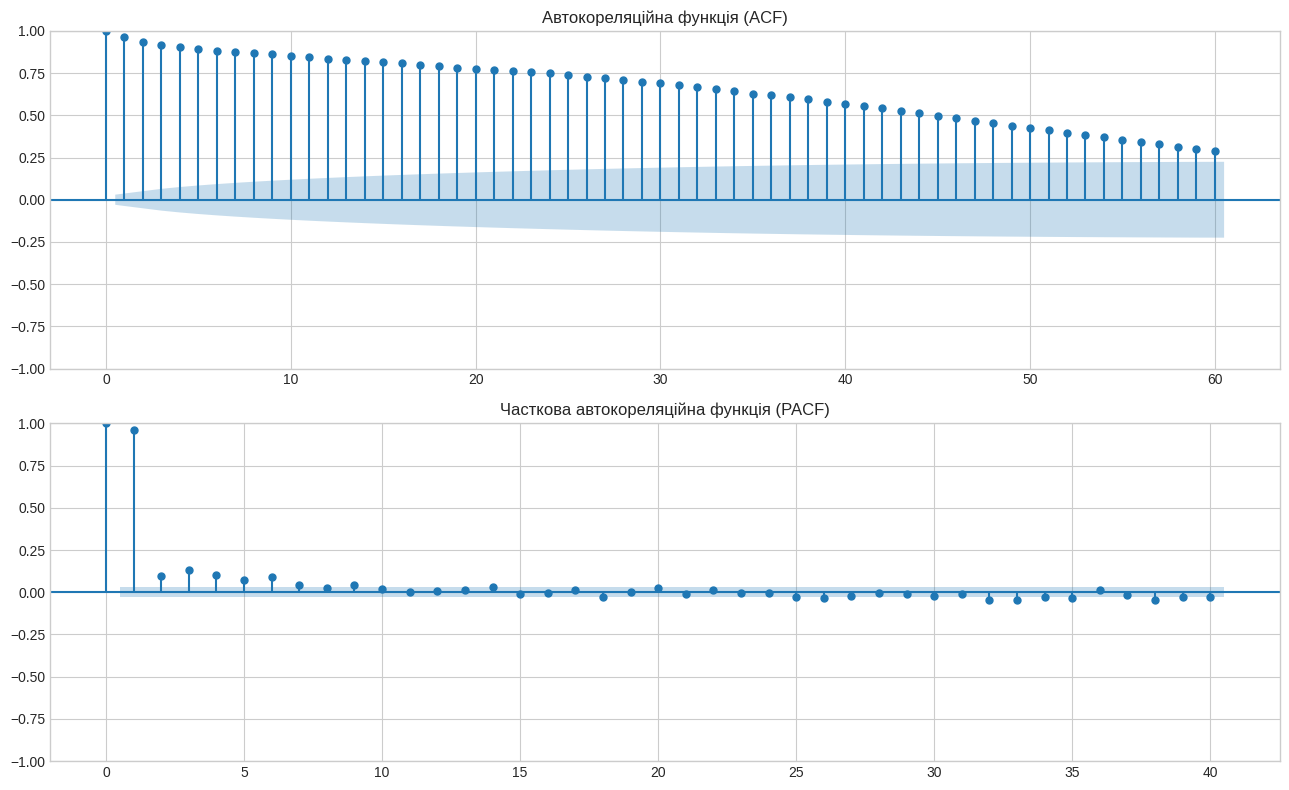

In [13]:
# Для графіків обмежуємо кількість лагів, щоб уникнути надмірного навантаження.
nlags = min(60, max(1, len(series) // 2 - 1))
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
plot_acf(series, lags=nlags, ax=axes[0])
axes[0].set_title("Автокореляційна функція (ACF)")
plot_pacf(series, lags=min(nlags, 40), method="ywm", ax=axes[1])
axes[1].set_title("Часткова автокореляційна функція (PACF)")
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

Train: 3399 спостережень, від 2013-04-14 до 2022-08-03
Test:  850 спостережень, від 2022-08-04 до 2024-11-30


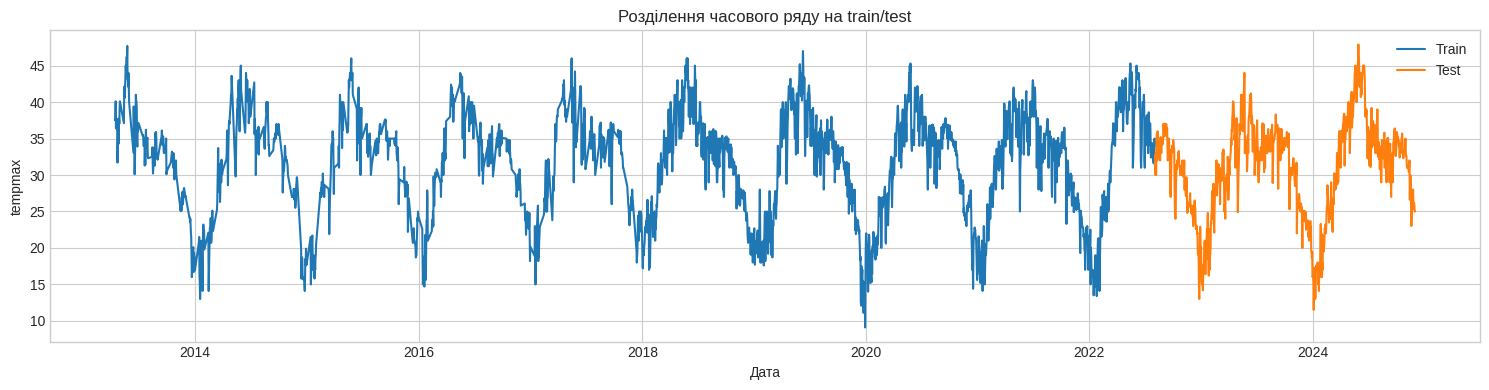

In [14]:
if len(series) < 100:
    print("Увага: ряд короткий, тому результати моделей можуть бути нестабільними.")

split_idx = int(len(series) * 0.8)
train = series.iloc[:split_idx]
test = series.iloc[split_idx:]

print(f"Train: {len(train)} спостережень, від {train.index.min().date()} до {train.index.max().date()}")
print(f"Test:  {len(test)} спостережень, від {test.index.min().date()} до {test.index.max().date()}")

plt.figure(figsize=(15, 4))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.title("Розділення часового ряду на train/test")
plt.xlabel("Дата")
plt.ylabel(TARGET_COL)
plt.legend()
plt.tight_layout()
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [15]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    # MAPE нестабільна, коли фактичні значення близькі до нуля.
    eps = 1e-8
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), eps))) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [16]:
# Базова модель ARIMA(5,1,0). За результатами ACF/PACF параметри можна змінити.
# У разі помилки збіжності використовується простіша ARIMA(1,1,1).
try:
    arima_model = ARIMA(train, order=(5, 1, 0), enforce_stationarity=False, enforce_invertibility=False)
    arima_fit = arima_model.fit()
except Exception as e:
    print("Не вдалося навчити ARIMA(5,1,0):", e)
    arima_model = ARIMA(train, order=(1, 1, 1), enforce_stationarity=False, enforce_invertibility=False)
    arima_fit = arima_model.fit()

arima_pred = pd.Series(np.asarray(arima_fit.forecast(steps=len(test))), index=test.index, name="ARIMA")
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 3399
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -6835.106
Date:                Wed, 21 Oct 2026   AIC                          13682.212
Time:                        18:35:14   BIC                          13718.988
Sample:                    04-14-2013   HQIC                         13695.358
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1582      0.013    -12.396      0.000      -0.183      -0.133
ar.L2         -0.1896      0.015    -12.781      0.000      -0.219      -0.161
ar.L3         -0.1406      0.017     -8.451      0.0

In [18]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# Навчання базової моделі ARIMA(5, 1, 0)
try:
    arima_model = ARIMA(
        train,
        order=(5, 1, 0),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    arima_fit = arima_model.fit()

except Exception as e:
    print("Не вдалося навчити ARIMA(5,1,0):", e)
    print("Використовується спрощена модель ARIMA(1,1,1).")

    arima_model = ARIMA(
        train,
        order=(1, 1, 1),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    arima_fit = arima_model.fit()

# Прогноз на тестовому періоді
arima_pred = pd.Series(
    np.asarray(arima_fit.forecast(steps=len(test))),
    index=test.index,
    name="ARIMA"
)

# Виведення статистичного звіту навченої моделі
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 3399
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -6835.106
Date:                Wed, 21 Oct 2026   AIC                          13682.212
Time:                        18:35:36   BIC                          13718.988
Sample:                    04-14-2013   HQIC                         13695.358
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1582      0.013    -12.396      0.000      -0.183      -0.133
ar.L2         -0.1896      0.015    -12.781      0.000      -0.219      -0.161
ar.L3         -0.1406      0.017     -8.451      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

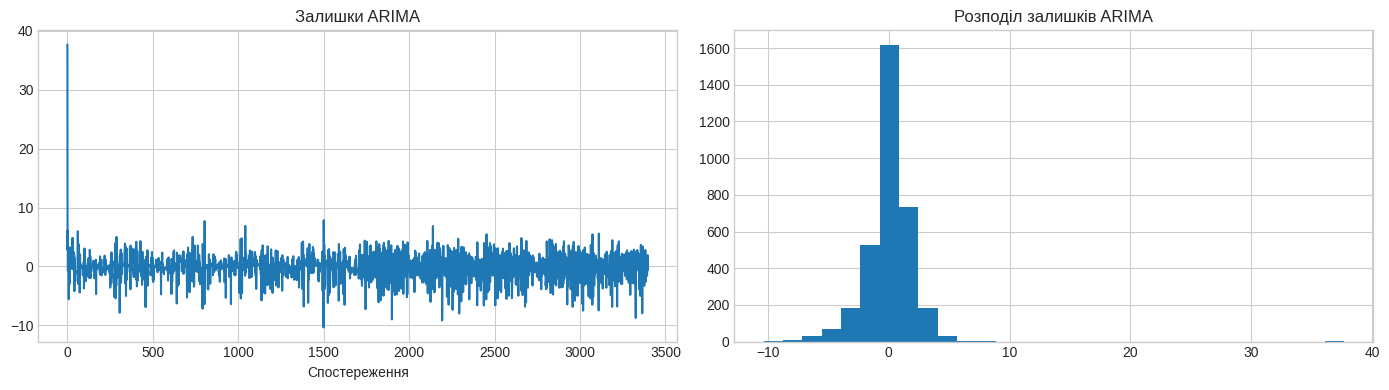

,lb_stat,lb_pvalue
10,23.85687,0.00799


Метрики ARIMA: {'MAE': 5.251120287522108, 'RMSE': np.float64(7.118020928538984), 'MAPE (%)': np.float64(21.622416615412003)}


In [19]:
residuals = pd.Series(arima_fit.resid).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuals.values)
axes[0].set_title("Залишки ARIMA")
axes[0].set_xlabel("Спостереження")
axes[1].hist(residuals, bins=30)
axes[1].set_title("Розподіл залишків ARIMA")
plt.tight_layout()
plt.show()

try:
    display(acorr_ljungbox(residuals, lags=[10], return_df=True))
except Exception as e:
    print("Не вдалося виконати тест Ljung–Box:", e)

print("Метрики ARIMA:", calculate_metrics(test, arima_pred))

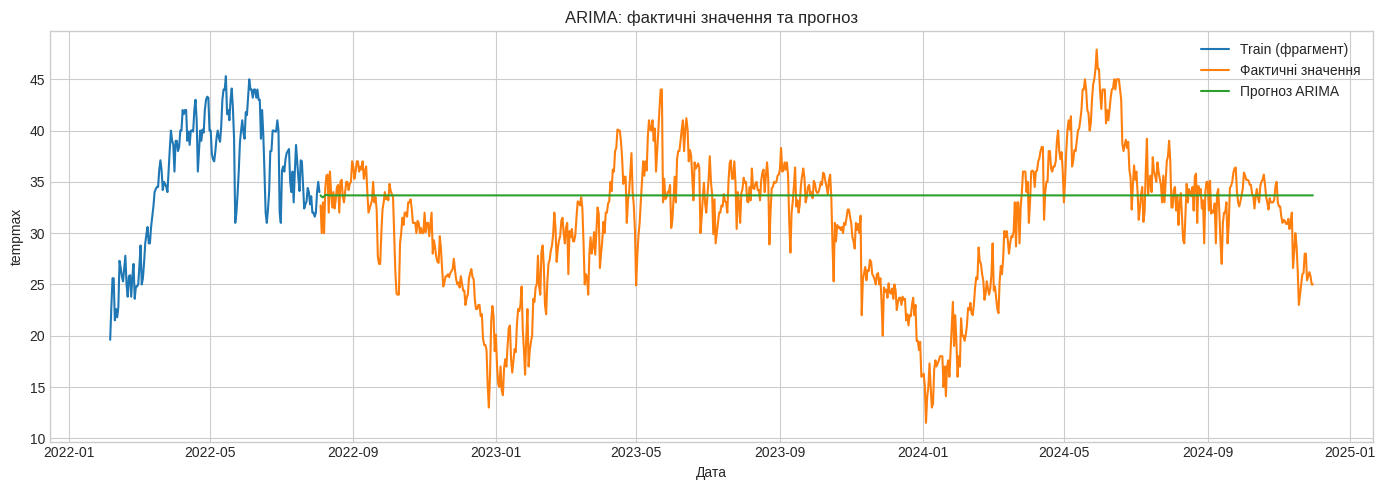

In [20]:
plt.figure(figsize=(14, 5))
plt.plot(train.index[-min(180, len(train)):], train.iloc[-min(180, len(train)):], label="Train (фрагмент)")
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(arima_pred.index, arima_pred, label="Прогноз ARIMA")
plt.title("ARIMA: фактичні значення та прогноз")
plt.xlabel("Дата")
plt.ylabel(TARGET_COL)
plt.legend()
plt.tight_layout()
plt.show()


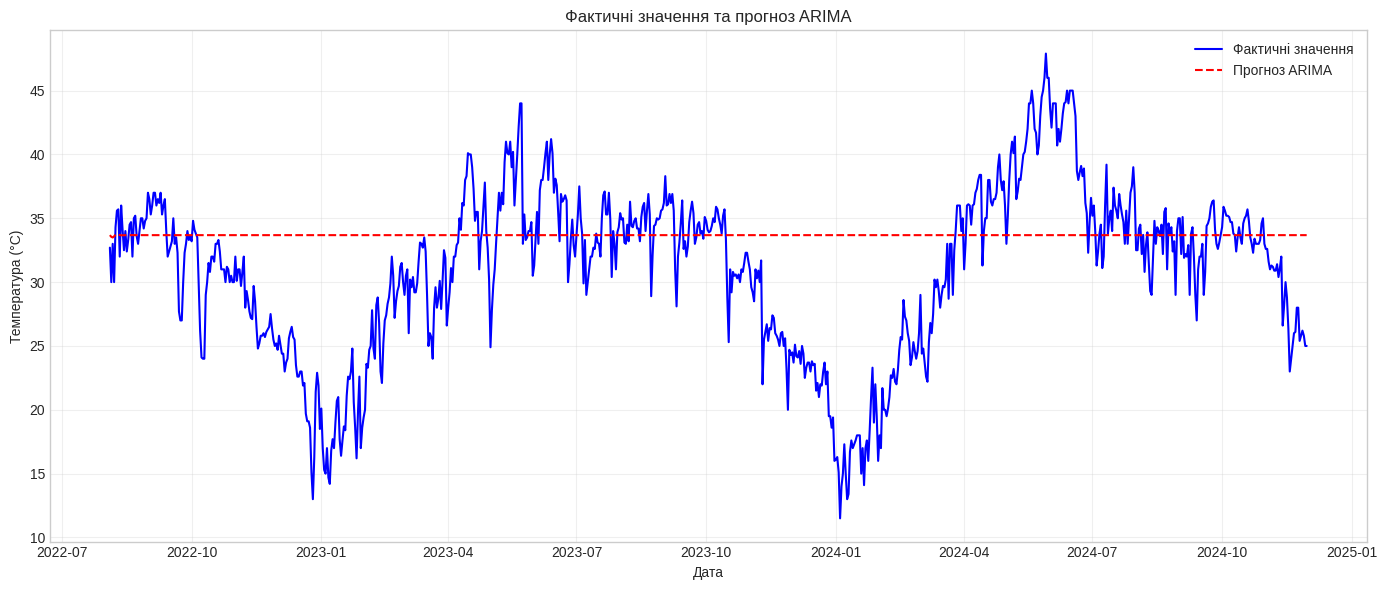

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test.values,
    label="Фактичні значення",
    color="blue"
)

plt.plot(
    arima_pred.index,
    arima_pred.values,
    label="Прогноз ARIMA",
    color="red",
    linestyle="--"
)

plt.title("Фактичні значення та прогноз ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [22]:
%pip -q install prophet


In [23]:
print(df.columns.tolist())

['Unnamed: 0', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


In [24]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

LOOKBACK = 30
RANDOM_STATE = 42

# Целевой ряд — средняя температура
series = df["temp"].astype(float).values.reshape(-1, 1)

# Разделение по времени: 80% обучение, 20% тест
split_idx = int(len(series) * 0.8)

# Масштабирование: обучаем scaler только на обучающей части
scaler = MinMaxScaler()
scaler.fit(series[:split_idx])
all_scaled = scaler.transform(series)

# Создание последовательностей для LSTM
X, y = [], []

for i in range(LOOKBACK, len(all_scaled)):
    X.append(all_scaled[i - LOOKBACK:i, 0])
    y.append(all_scaled[i, 0])

X = np.array(X).reshape(-1, LOOKBACK, 1)
y = np.array(y)

# Разделение последовательностей по времени
train_end = split_idx - LOOKBACK

X_train = X[:train_end]
y_train = y[:train_end]

X_test = X[train_end:]
y_test = y[train_end:]

print("Обучающие данные:", X_train.shape, y_train.shape)
print("Тестовые данные:", X_test.shape, y_test.shape)

Обучающие данные: (2814, 30, 1) (2814,)
Тестовые данные: (712, 30, 1) (712,)


In [25]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(RANDOM_STATE)

lstm_model = Sequential([
    LSTM(32, input_shape=(LOOKBACK, 1), return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

lstm_model.compile(optimizer="adam", loss="mse")
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = lstm_model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

lstm_model.summary()

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.1179 - val_loss: 0.0106
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0147 - val_loss: 0.0095
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0111 - val_loss: 0.0053
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0092 - val_loss: 0.0049
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0081 - val_loss: 0.0055
Epoch 6/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0072 - val_loss: 0.0041
Epoch 7/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0070 - val_loss: 0.0039
Epoch 8/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0065 - val_loss: 0.0039
Epoch 9/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0064 - val_loss: 0.0036
Epoch 10/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0055 - val_loss: 0.0039
Epoch 11/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0053 - val_loss: 0.0047
Epoch 12/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0053 - val_l

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,693 (57.40 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,796 (38.27 KB)

Прогноз

In [26]:
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)

# Переводим прогноз и реальные значения обратно в градусы
lstm_pred_values = scaler.inverse_transform(
    lstm_pred_scaled.reshape(-1, 1)
).ravel()

lstm_actual_values = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

# Индексы дат тестового периода
lstm_test_index = df.index[split_idx:]

lstm_pred = pd.Series(
    lstm_pred_values,
    index=lstm_test_index,
    name="LSTM"
)

lstm_actual = pd.Series(
    lstm_actual_values,
    index=lstm_test_index,
    name="Actual"
)

print("Метрики LSTM:", calculate_metrics(lstm_actual, lstm_pred))


Метрики LSTM: {'MAE': 1.4375178342454884, 'RMSE': np.float64(1.8300433077835723), 'MAPE (%)': np.float64(6.247821423595157)}


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


MAE Prophet: 2.4872
RMSE Prophet: 3.2635
MAPE Prophet: 9.00%


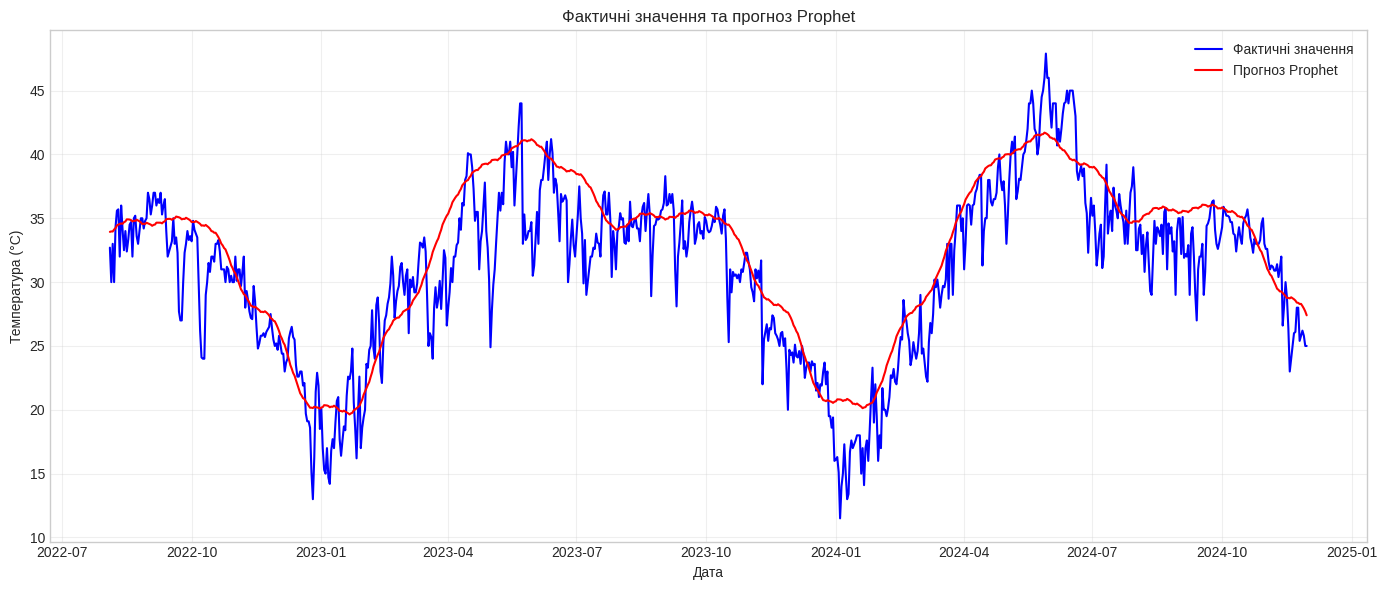

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Підготовка даних для Prophet
prophet_train = pd.DataFrame({
    "ds": pd.to_datetime(train.index),
    "y": train.values
})

prophet_test = pd.DataFrame({
    "ds": pd.to_datetime(test.index),
    "y": test.values
})

# Створення та навчання моделі
prophet_model = Prophet()
prophet_model.fit(prophet_train)

# Прогноз на тестовому періоді
prophet_forecast = prophet_model.predict(
    prophet_test[["ds"]]
)

# Фактичні значення та прогноз
prophet_actual = prophet_test["y"].to_numpy()
prophet_pred = prophet_forecast["yhat"].to_numpy()

# Обчислення MAE, RMSE, MAPE
mae = mean_absolute_error(prophet_actual, prophet_pred)
rmse = np.sqrt(mean_squared_error(prophet_actual, prophet_pred))

nonzero = prophet_actual != 0
if nonzero.any():
    mape = np.mean(
        np.abs(
            (prophet_actual[nonzero] - prophet_pred[nonzero])
            / prophet_actual[nonzero]
        )
    ) * 100
else:
    mape = np.nan

print(f"MAE Prophet: {mae:.4f}")
print(f"RMSE Prophet: {rmse:.4f}")
print(f"MAPE Prophet: {mape:.2f}%")

# Візуалізація фактичних значень і прогнозу
plt.figure(figsize=(14, 6))
plt.plot(
    prophet_test["ds"],
    prophet_actual,
    label="Фактичні значення",
    color="blue"
)
plt.plot(
    prophet_test["ds"],
    prophet_pred,
    label="Прогноз Prophet",
    color="red"
)

plt.title("Фактичні значення та прогноз Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

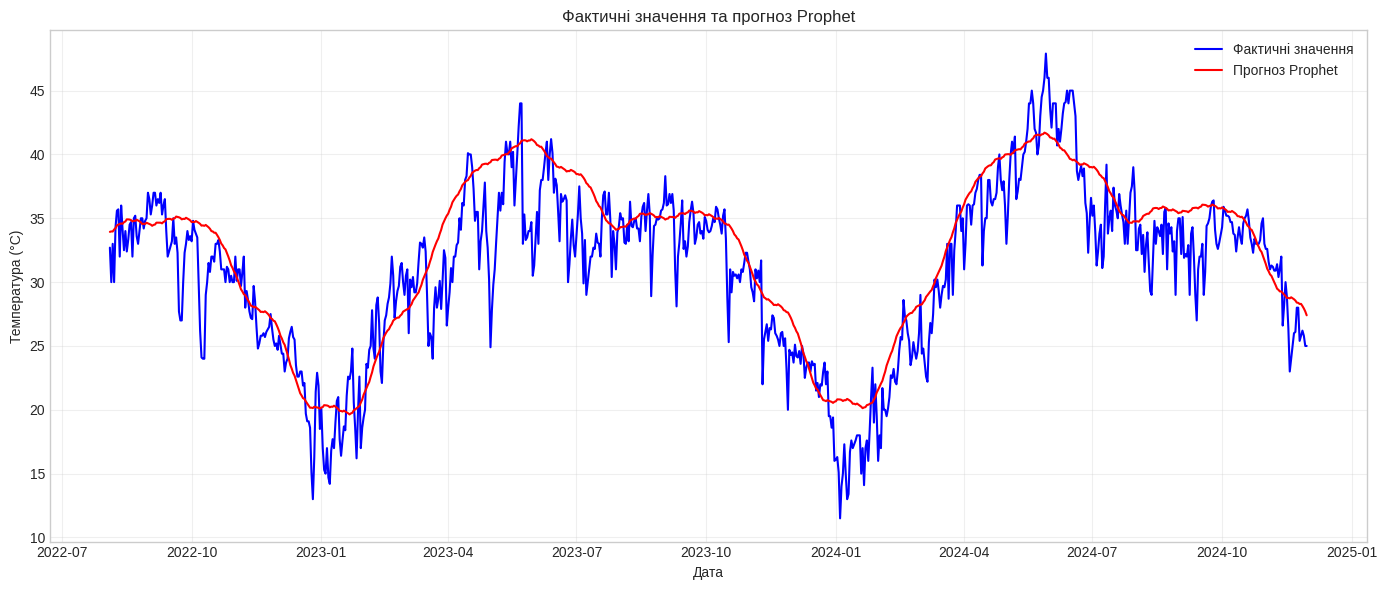

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    prophet_test["ds"],
    prophet_test["y"],
    label="Фактичні значення",
    color="blue"
)

plt.plot(
    prophet_test["ds"],
    prophet_forecast["yhat"],
    label="Прогноз Prophet",
    color="red"
)

plt.title("Фактичні значення та прогноз Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


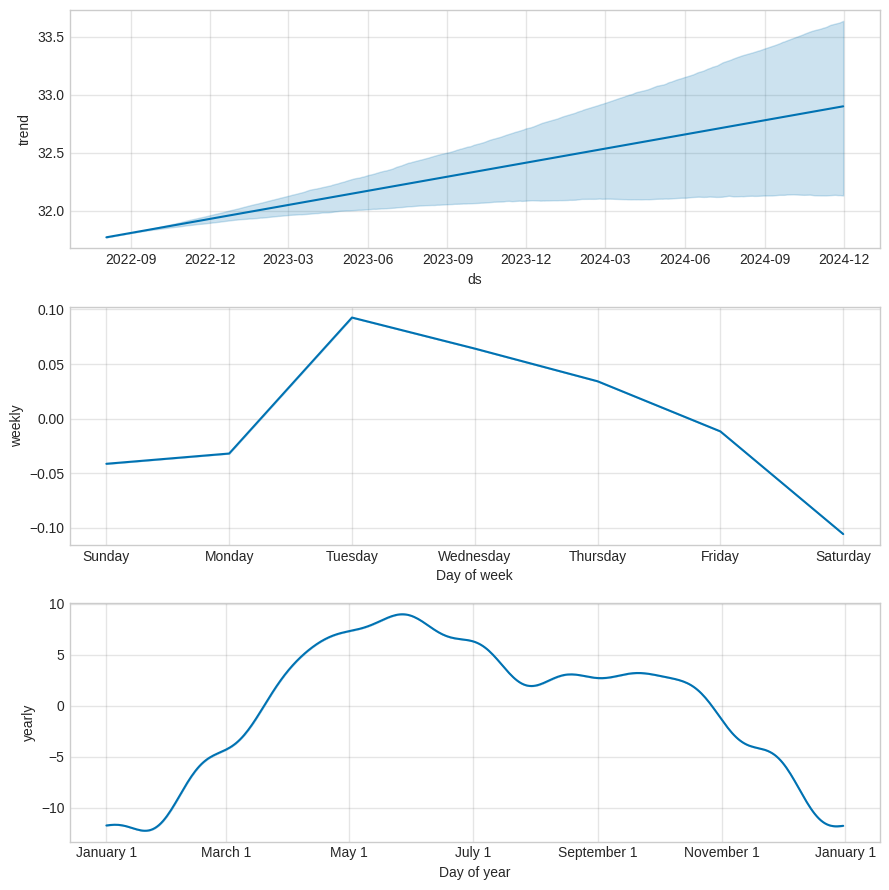

In [32]:
# Побудова компонентів моделі Prophet
prophet_model.plot_components(prophet_forecast)

plt.tight_layout()
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [33]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Цільовий часовий ряд — температура
series = df["temp"].astype(float).values.reshape(-1, 1)

# Розділення даних у хронологічному порядку: 80% / 20%
LOOKBACK = 30
RANDOM_STATE = 42
split_idx = int(len(series) * 0.8)

# Масштабування на основі навчальних даних
scaler = MinMaxScaler()
scaler.fit(series[:split_idx])
scaled_series = scaler.transform(series)

# Формування послідовностей
X, y = [], []

for i in range(LOOKBACK, len(scaled_series)):
    X.append(scaled_series[i - LOOKBACK:i, 0])
    y.append(scaled_series[i, 0])

X = np.array(X).reshape(-1, LOOKBACK, 1)
y = np.array(y)

# Розділення на навчальну та тестову вибірки
train_end = split_idx - LOOKBACK

X_train = X[:train_end]
y_train = y[:train_end]

X_test = X[train_end:]
y_test = y[train_end:]

print("Розмір X_train:", X_train.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір X_test:", X_test.shape)
print("Розмір y_test:", y_test.shape)


Розмір X_train: (2814, 30, 1)
Розмір y_train: (2814,)
Розмір X_test: (712, 30, 1)
Розмір y_test: (712,)


In [34]:
# Розділення послідовностей без перемішування
split_idx = int(len(df) * 0.8)
train_end = split_idx - LOOKBACK

X_train = X[:train_end]
y_train = y[:train_end]

X_test = X[train_end:]
y_test = y[train_end:]

print("Розмір тренувальної вибірки:", X_train.shape, y_train.shape)
print("Розмір тестової вибірки:", X_test.shape, y_test.shape)


Розмір тренувальної вибірки: (2814, 30, 1) (2814,)
Розмір тестової вибірки: (712, 30, 1) (712,)


In [35]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Фіксація випадкових значень
tf.random.set_seed(42)

# Побудова архітектури LSTM-моделі
lstm_model = Sequential([
    LSTM(32, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

# Компіляція моделі
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Виведення архітектури моделі
lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
from tensorflow.keras.callbacks import EarlyStopping

# Зупинка навчання, якщо помилка валідації не покращується
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Навчання LSTM-моделі
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Навчання LSTM завершено.")

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0263 - mae: 0.1177 - val_loss: 0.0060 - val_mae: 0.0643
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0099 - mae: 0.0780 - val_loss: 0.0041 - val_mae: 0.0503
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0079 - mae: 0.0694 - val_loss: 0.0042 - val_mae: 0.0508
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0071 - mae: 0.0662 - val_loss: 0.0045 - val_mae: 0.0537
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0064 - mae: 0.0625 - val_loss: 0.0041 - val_mae: 0.0508
Epoch 6/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0061 - mae: 0.0606 - val_loss: 0.0048 - val_mae: 0.0561
Epoch 7/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0060 - mae: 0.0603 - val_loss: 0.0043 - val_mae: 0.0523
Навчання LSTM завершено.


In [2]:
lstm_model.summary()


NameError: name 'lstm_model' is not defined

Результати LSTM:
MAE:  1.6005
RMSE: 1.9952
MAPE: 7.13%


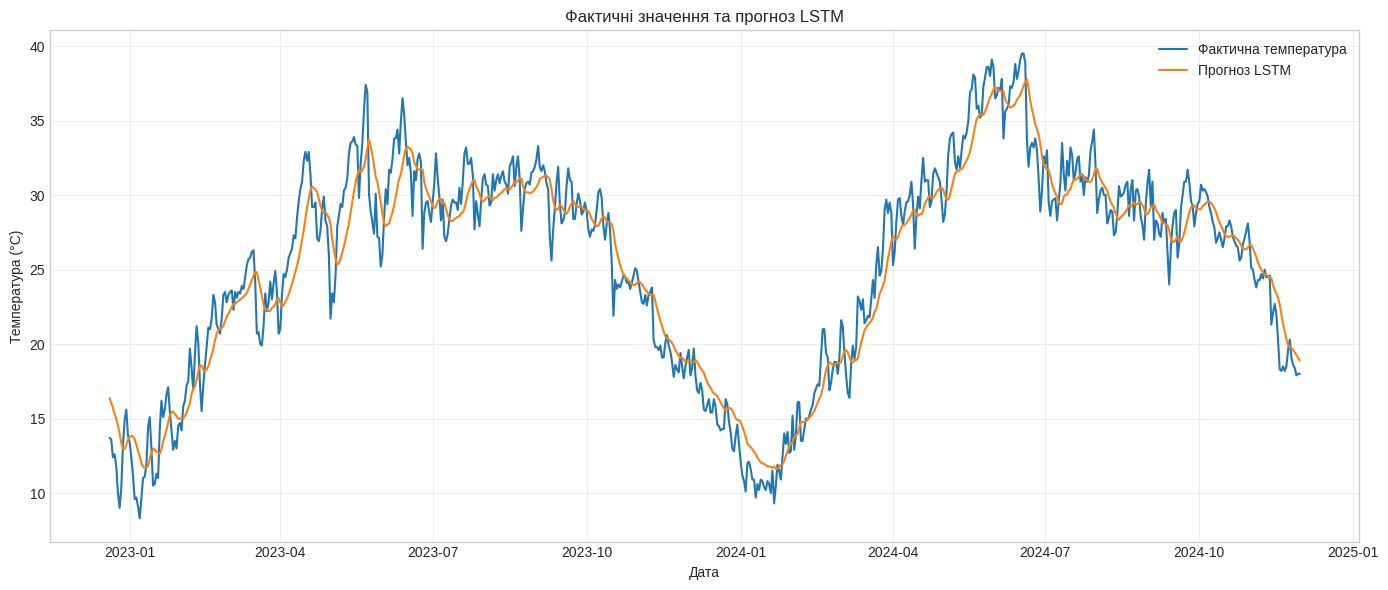

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Отримання прогнозу LSTM
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)

# 2. Зворотне масштабування до температури в °C
lstm_actual = scaler.inverse_transform(
    np.asarray(y_test).reshape(-1, 1)
).ravel()

lstm_pred = scaler.inverse_transform(
    np.asarray(lstm_pred_scaled).reshape(-1, 1)
).ravel()

# 3. Часові мітки тестового прогнозу
lstm_dates = pd.to_datetime(df.index[-len(lstm_actual):])

# Якщо індекс df не містить дат, використовуйте дати з test.index,
# якщо вони відповідають довжині тестового прогнозу.
if len(lstm_dates) != len(lstm_actual):
    raise ValueError("Кількість часових міток не збігається з прогнозом.")

# 4. Обчислення метрик LSTM
lstm_mae = mean_absolute_error(lstm_actual, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(lstm_actual, lstm_pred))

nonzero = lstm_actual != 0
lstm_mape = (
    np.mean(np.abs(
        (lstm_actual[nonzero] - lstm_pred[nonzero]) /
        lstm_actual[nonzero]
    )) * 100
    if nonzero.any() else np.nan
)

print("Результати LSTM:")
print(f"MAE:  {lstm_mae:.4f}")
print(f"RMSE: {lstm_rmse:.4f}")
print(f"MAPE: {lstm_mape:.2f}%")

# 5. Візуалізація фактичних значень та прогнозу
plt.figure(figsize=(14, 6))
plt.plot(lstm_dates, lstm_actual, label="Фактична температура")
plt.plot(lstm_dates, lstm_pred, label="Прогноз LSTM")
plt.title("Фактичні значення та прогноз LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Порівняння моделей

In [39]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Формуємо ряди фактичних значень і прогнозів з часовими індексами
actual_series = pd.Series(
    np.asarray(test).reshape(-1),
    index=pd.to_datetime(test.index)
)

arima_series = pd.Series(
    np.asarray(arima_pred).reshape(-1),
    index=pd.to_datetime(test.index[-len(arima_pred):])
)

prophet_series = pd.Series(
    np.asarray(prophet_pred).reshape(-1),
    index=pd.to_datetime(prophet_test["ds"])
)

lstm_series = pd.Series(
    np.asarray(lstm_pred).reshape(-1),
    index=pd.to_datetime(lstm_dates)
)

# Знаходимо дати, спільні для фактичних значень і всіх прогнозів
comparison = pd.concat(
    [
        actual_series.rename("Факт"),
        arima_series.rename("ARIMA"),
        prophet_series.rename("Prophet"),
        lstm_series.rename("LSTM")
    ],
    axis=1,
    join="inner"
).dropna()

if comparison.empty:
    raise ValueError(
        "Немає спільних дат. Перевір часові індекси тестової вибірки "
        "та прогнозів моделей."
    )

# Обчислюємо метрики на однакових датах
actual = comparison["Факт"].to_numpy()
results = []

for model_name in ["ARIMA", "Prophet", "LSTM"]:
    pred = comparison[model_name].to_numpy()

    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    nonzero = actual != 0
    mape = (
        np.mean(np.abs(
            (actual[nonzero] - pred[nonzero]) / actual[nonzero]
        )) * 100
        if nonzero.any() else np.nan
    )

    results.append({
        "Модель": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

results_df = pd.DataFrame(results).set_index("Модель")

print(f"Кількість спільних дат для порівняння: {len(comparison)}")
display(results_df.round(4))

print("Найкраща модель за MAE:", results_df["MAE"].idxmin())
print("Найкраща модель за RMSE:", results_df["RMSE"].idxmin())
print("Найкраща модель за MAPE:", results_df["MAPE (%)"].idxmin())

Кількість спільних дат для порівняння: 712


,MAE,RMSE,MAPE (%)
Модель,,,
ARIMA,5.4881,7.4307,22.9078
Prophet,2.5958,3.3560,9.4435
LSTM,5.8462,6.4181,19.2815


Найкраща модель за MAE: Prophet
Найкраща модель за RMSE: Prophet
Найкраща модель за MAPE: Prophet


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У ході лабораторної роботи було проведено аналіз часового ряду температури повітря та побудовано моделі прогнозування ARIMA, Prophet і LSTM. Для оцінювання якості прогнозів використано метрики MAE, RMSE і MAPE. За їх допомогою порівняно відхилення прогнозованих значень від фактичних.

Найкращою моделлю є та, яка продемонструвала найменші значення MAE, RMSE і MAPE. За результатами порівняння було визначено модель із найвищою точністю прогнозування температури повітря. Отримані результати показали, що використання різних методів прогнозування дає змогу оцінити їхню ефективність для аналізу часових рядів.